# Partie 2 — Polarisation politique et attitudes : une cartographie des corrélations

**Question.** La position politique des Européens est-elle liée à leurs opinions sur d'autres sujets (immigration, redistribution, mœurs, religion, climat, institutions, santé) ? Si oui, lesquels ?

Nous utilisons les deux mesures de polarisation créées en partie 1 :
- **la position** gauche-droite `lrscale`, de 0 (gauche) à 10 (droite) ;
- **l'extrémité** `lrscaleabs` $= |\text{lrscale} - 5|$, de 0 (centre) à 5 (très à gauche ou très à droite).

Nous reproduisons deux figures de référence :
- **DellaPosta, Shi et Macy (2015), figure 1 :** les opinions sont-elles toutes un peu corrélées entre elles ?
- **Baldassarri et Gelman (2008), figure 2 :** quels sujets sont les plus liés à la position politique ?

In [1]:
import sys
sys.path.append("src")
import pandas as pd
import partie2_correlations as p2

pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 2)

## 2.1 Les données et la polarisation par pays

On part de la base nettoyée de la partie 1, en excluant Israël pour rester en Europe. On étudie les **49 questions d'opinion** que la partie 1 a regroupées en **10 domaines**. Comme en partie 1, on écarte une question sur le genre (« les femmes ont un meilleur sens moral »), qui n'est pas corrélée aux autres. Chaque question est notée de 0 à 1, une valeur haute voulant dire que l'énoncé est vrai : par exemple, pour « Same-sex couples may adopt », 1 = tout à fait d'accord.

In [2]:
df = p2.charger_base("../output/ess11_propre.csv")
items = p2.liste_items(df)

tableau = p2.tableau_pays(df)
tableau

46,549 répondants, 28 pays


,N,no_answer_lr_%,mean_position,mean_extremity
country,,,,
PL,1442,10.06,5.63,2.19
HU,2118,12.70,5.51,2.18
ME,1609,15.29,4.07,2.06
CY,685,11.82,5.20,1.91
SK,1442,11.23,4.77,1.88
SE,1230,2.20,4.93,1.87
NO,1337,2.47,5.15,1.84
FI,1563,3.01,5.46,1.80
BG,2239,18.98,5.38,1.79


Part au centre (5) : 31.6 %
Part aux extrêmes (0-1 ou 9-10) : 12.8 %


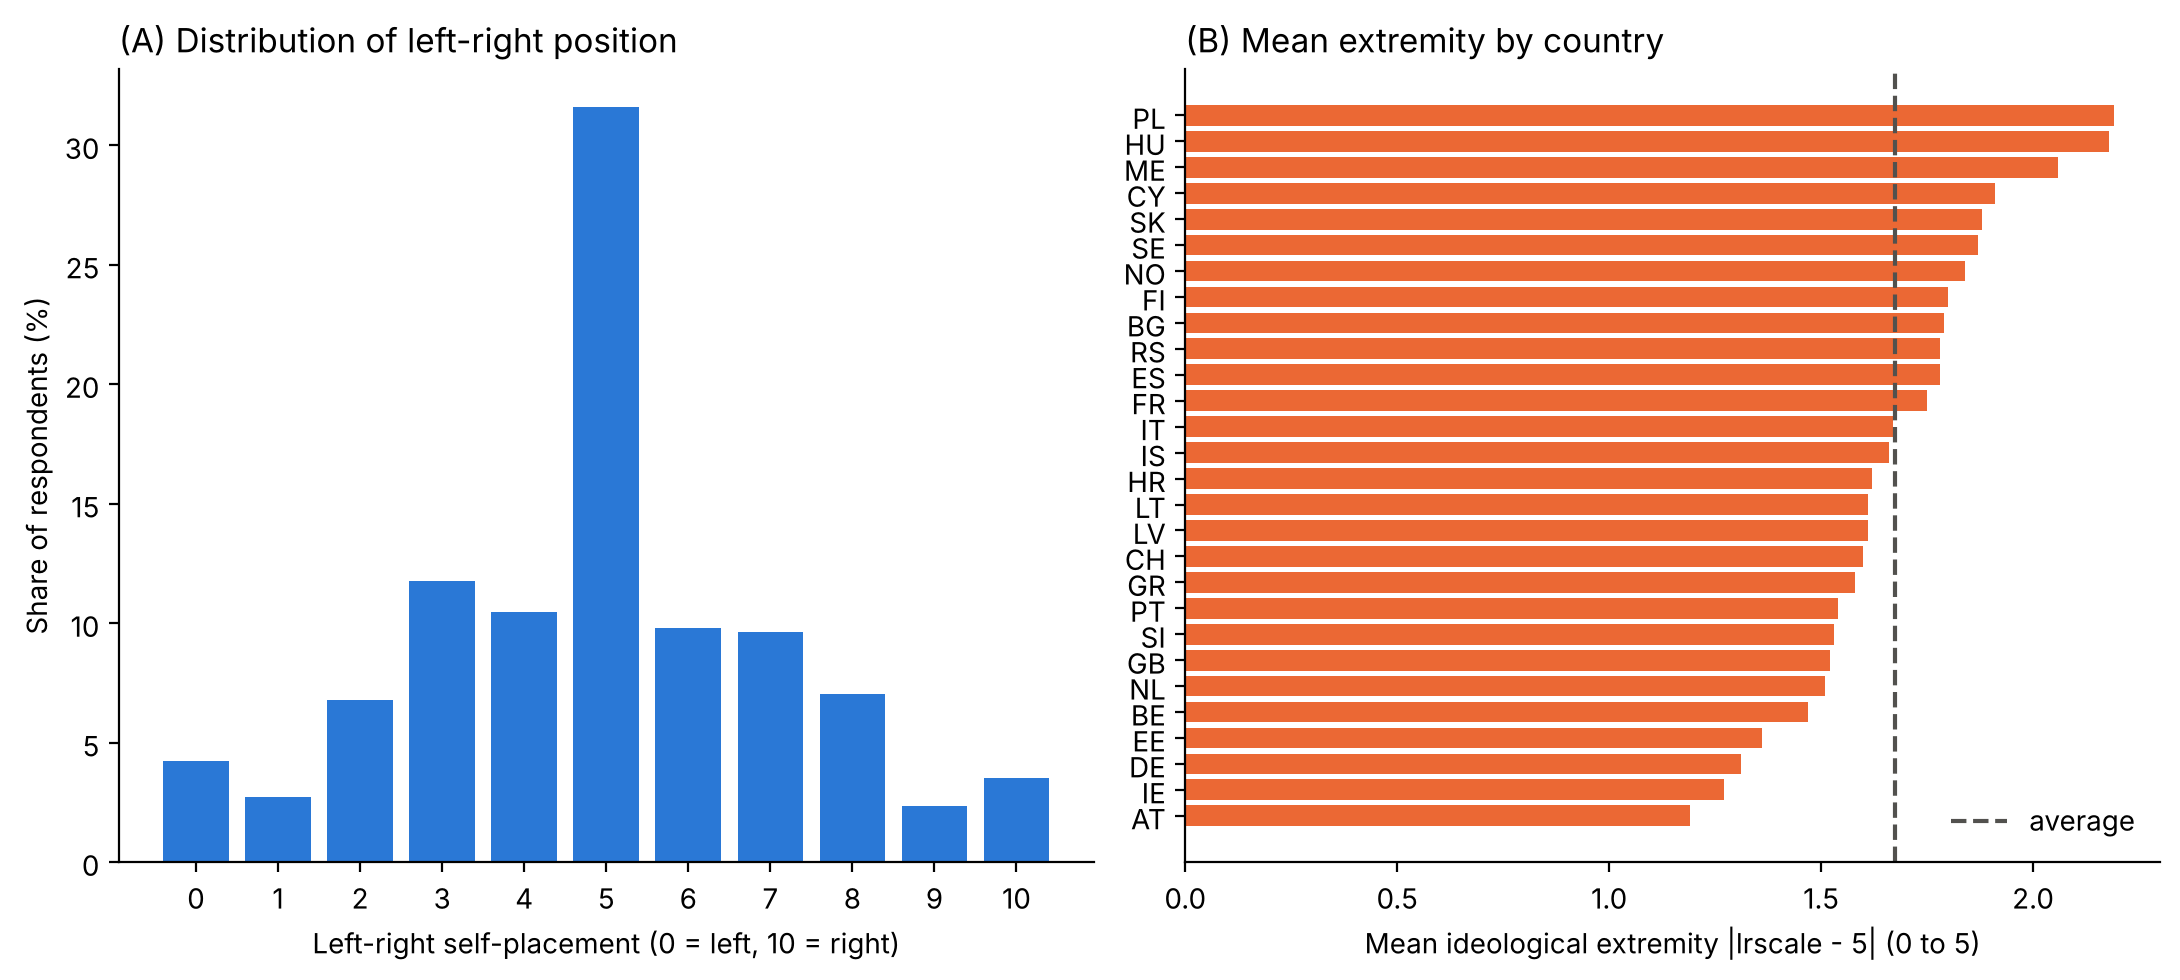

In [3]:
parts = p2.figure_polarisation(df, tableau)
print(f"Part au centre (5) : {parts[5]:.1f} %")
print(f"Part aux extrêmes (0-1 ou 9-10) : {parts[[0, 1, 9, 10]].sum():.1f} %")

**À retenir.**
- **Un tiers des Européens (32 %) se placent exactement au centre.** Seuls 13 % se placent aux extrêmes.
- **La polarisation n'est pas réservée à l'Est.** La Pologne et la Hongrie sont les plus polarisées, mais la Suède, la Norvège et la Finlande sont aussi au-dessus de la moyenne. L'Autriche, l'Irlande et l'Allemagne sont les moins polarisées.
- **Une limite :** beaucoup de personnes ne se placent pas sur l'échelle en Serbie et en Lettonie (plus de 30 %, contre moins de 3 % en Suède). Dans ces pays, nos résultats portent sur les répondants les plus politisés.

## 2.2 Méthode

- **Corrélation de Pearson pondérée** par le poids d'analyse de l'ESS (`anweight`). Pour deux variables, on garde les personnes qui ont répondu aux deux questions. La seule exception est la figure 1 : comme elle décrit « les Européens », chaque pays y pèse selon sa population.
- **Pays par pays, puis moyenne simple sur les 28 pays.** Si on mélangeait tous les pays, on mesurerait aussi des différences *entre* pays (certains pays sont à la fois plus à droite et plus religieux que d'autres), alors qu'on veut des liens *entre personnes*. La section 2.4 montre que cela change vraiment les résultats.
- **Corrélations partielles** : comme DellaPosta et al., on vérifie que les liens ne viennent pas seulement de la démographie. Dans chaque pays, on retire de chaque variable ce qu'expliquent l'âge, le sexe, le diplôme et le fait de vivre en ville (régression linéaire simple, non pondérée), puis on corrèle ce qui reste avec la corrélation pondérée.

## 2.3 Les opinions sont-elles toutes corrélées entre elles ? (figure 1 de DellaPosta et al.)

On calcule la corrélation entre chaque paire de questions, soit 1 176 paires. Le calcul prend environ une minute.

Corrélation moyenne |r| : 0.12  (partielle : 0.11)
Même domaine : 0.32  |  domaines différents : 0.09


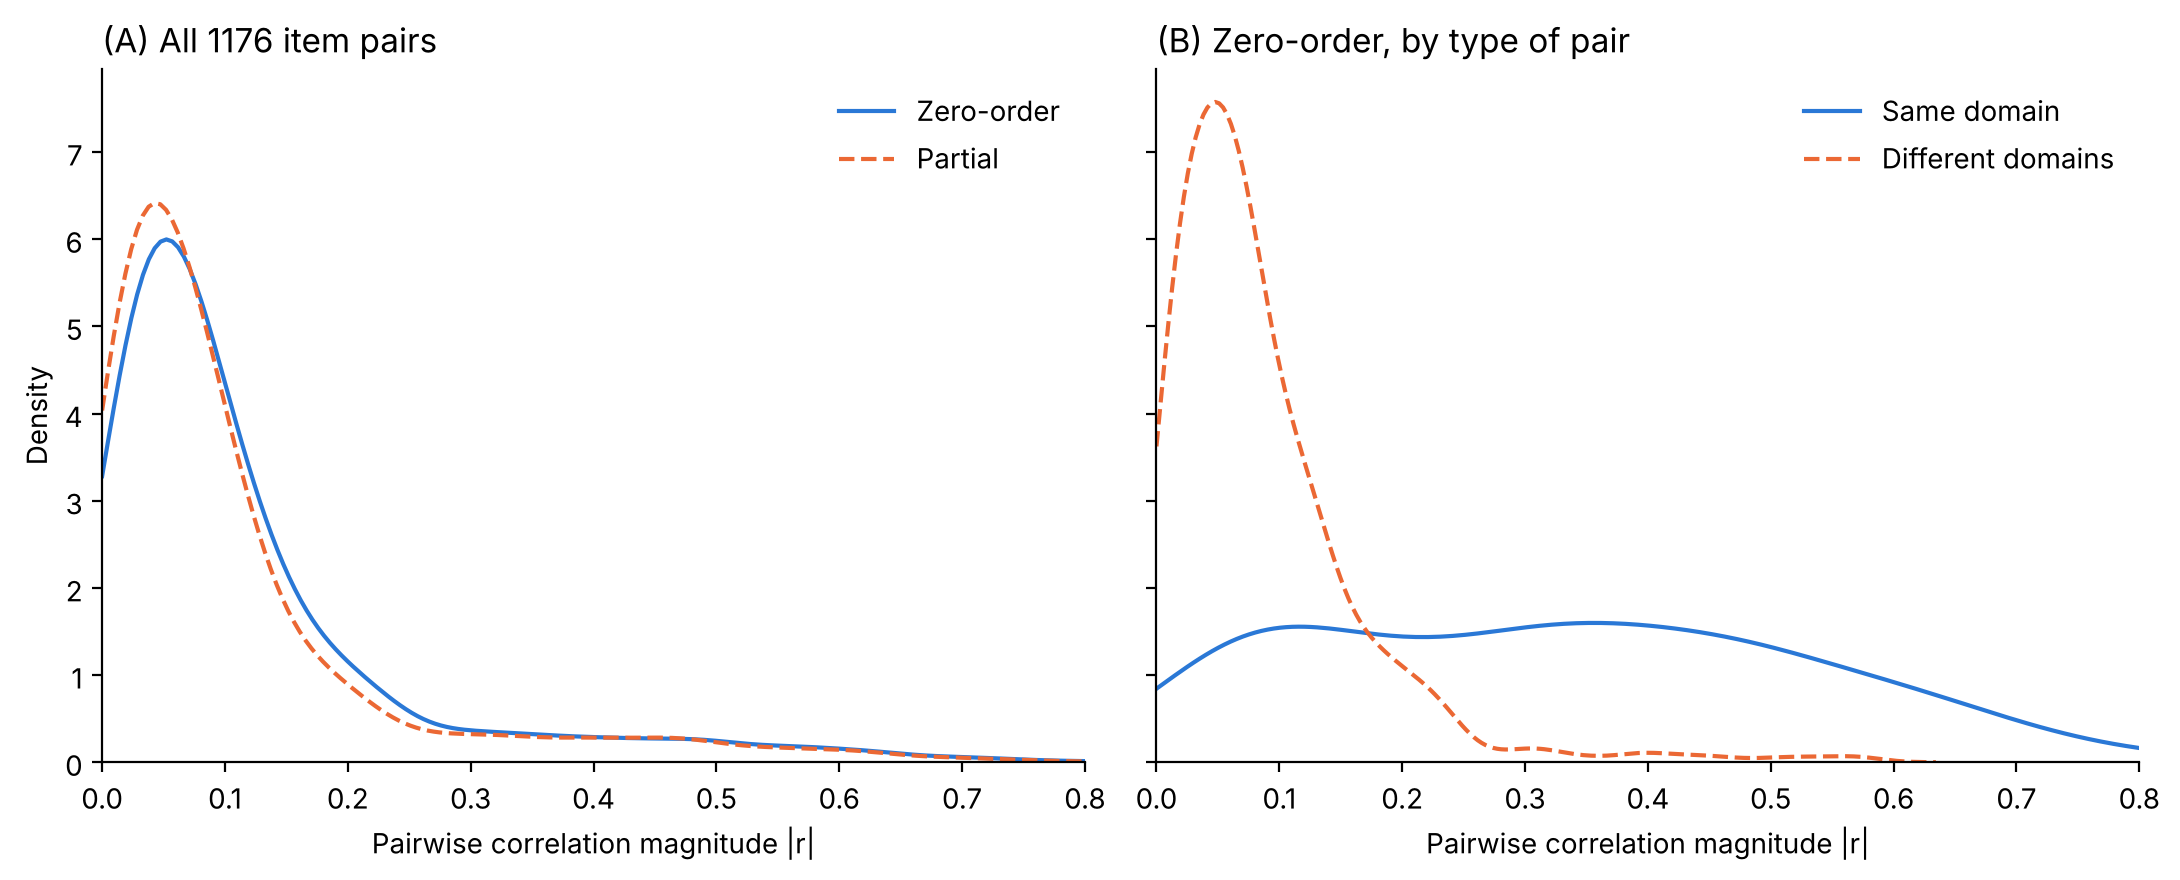

In [4]:
residus = p2.residus_controles(df, items)
paires = p2.table_paires(df, residus, items)
p2.figure_dellaposta(paires)

print(f"Corrélation moyenne |r| : {paires['r'].abs().mean():.2f}  (partielle : {paires['r_partial'].abs().mean():.2f})")
print(f"Même domaine : {paires[paires['same_group']]['r'].abs().mean():.2f}  |  "
      f"domaines différents : {paires[~paires['same_group']]['r'].abs().mean():.2f}")

**À retenir.**
- **Comme dans la figure de DellaPosta et al., la plupart des corrélations sont faibles mais rarement nulles,** avec quelques liens forts. La moyenne est de 0,12, du même ordre que sur les données américaines de l'article (environ 0,09).
- **Contrôler la démographie ne change presque rien** (de 0,12 à 0,11) : les opinions ne vont pas ensemble simplement parce qu'elles dépendent de l'âge ou du diplôme.
- **Les liens forts sont surtout entre questions d'un même domaine** (0,32, contre 0,09 entre domaines). Mais certains domaines différents sont nettement liés, comme le montre le tableau ci-dessous.

In [5]:
# paires de domaines différents, sans les paires satisfaction x confiance
# (très corrélées, jusqu'à 0,57, mais elles mesurent la même chose : le soutien au système politique)
soutien = ["Satisfaction", "Institutional trust"]
garder = ~paires["same_group"] & ~(paires["group_1"].isin(soutien) & paires["group_2"].isin(soutien))
entre_domaines = paires[garder].copy()
entre_domaines["abs_r"] = entre_domaines["r"].abs()
entre_domaines.sort_values("abs_r", ascending=False).head(12)[["item_1", "item_2", "r", "r_partial"]]

,item_1,item_2,r,r_partial
911,EU unification should go further,Trust in the European Parliament,0.38,0.37
162,Immigration good for the economy,EU unification should go further,0.32,0.30
206,Immigrants enrich cultural life,EU unification should go further,0.31,0.29
249,Immigrants make country a better place,EU unification should go further,0.31,0.29
912,EU unification should go further,Trust in the United Nations,0.30,0.29
261,Immigrants make country a better place,Trust in the European Parliament,0.29,0.27
218,Immigrants enrich cultural life,Trust in the European Parliament,0.28,0.26
174,Immigration good for the economy,Trust in the European Parliament,0.28,0.26
262,Immigrants make country a better place,Trust in the United Nations,0.25,0.23
55,Allow immigrants of different ethnicity,Same-sex couples may adopt,0.25,0.20


**Les « lattes » européens.** Deux paquets d'opinions ressortent :
- **l'immigration, l'Europe et la confiance dans les institutions internationales vont ensemble.** Être favorable à l'immigration va de pair avec le soutien à l'intégration européenne et la confiance dans le Parlement européen ou l'ONU ;
- **l'immigration et les droits LGBT vont aussi ensemble.** Ce sont deux sujets sans lien logique, mais les personnes ouvertes sur l'un le sont souvent sur l'autre. C'est exactement l'idée de DellaPosta et al.

## 2.4 Les sujets liés à la gauche et à la droite sont-ils les mêmes partout ?

On calcule maintenant la corrélation de chaque question avec la **position gauche-droite**, dans chaque pays. **Bleu** = opinion plus fréquente à gauche, **rouge** = plus fréquente à droite. La colonne `EUROPE` est la moyenne des pays.

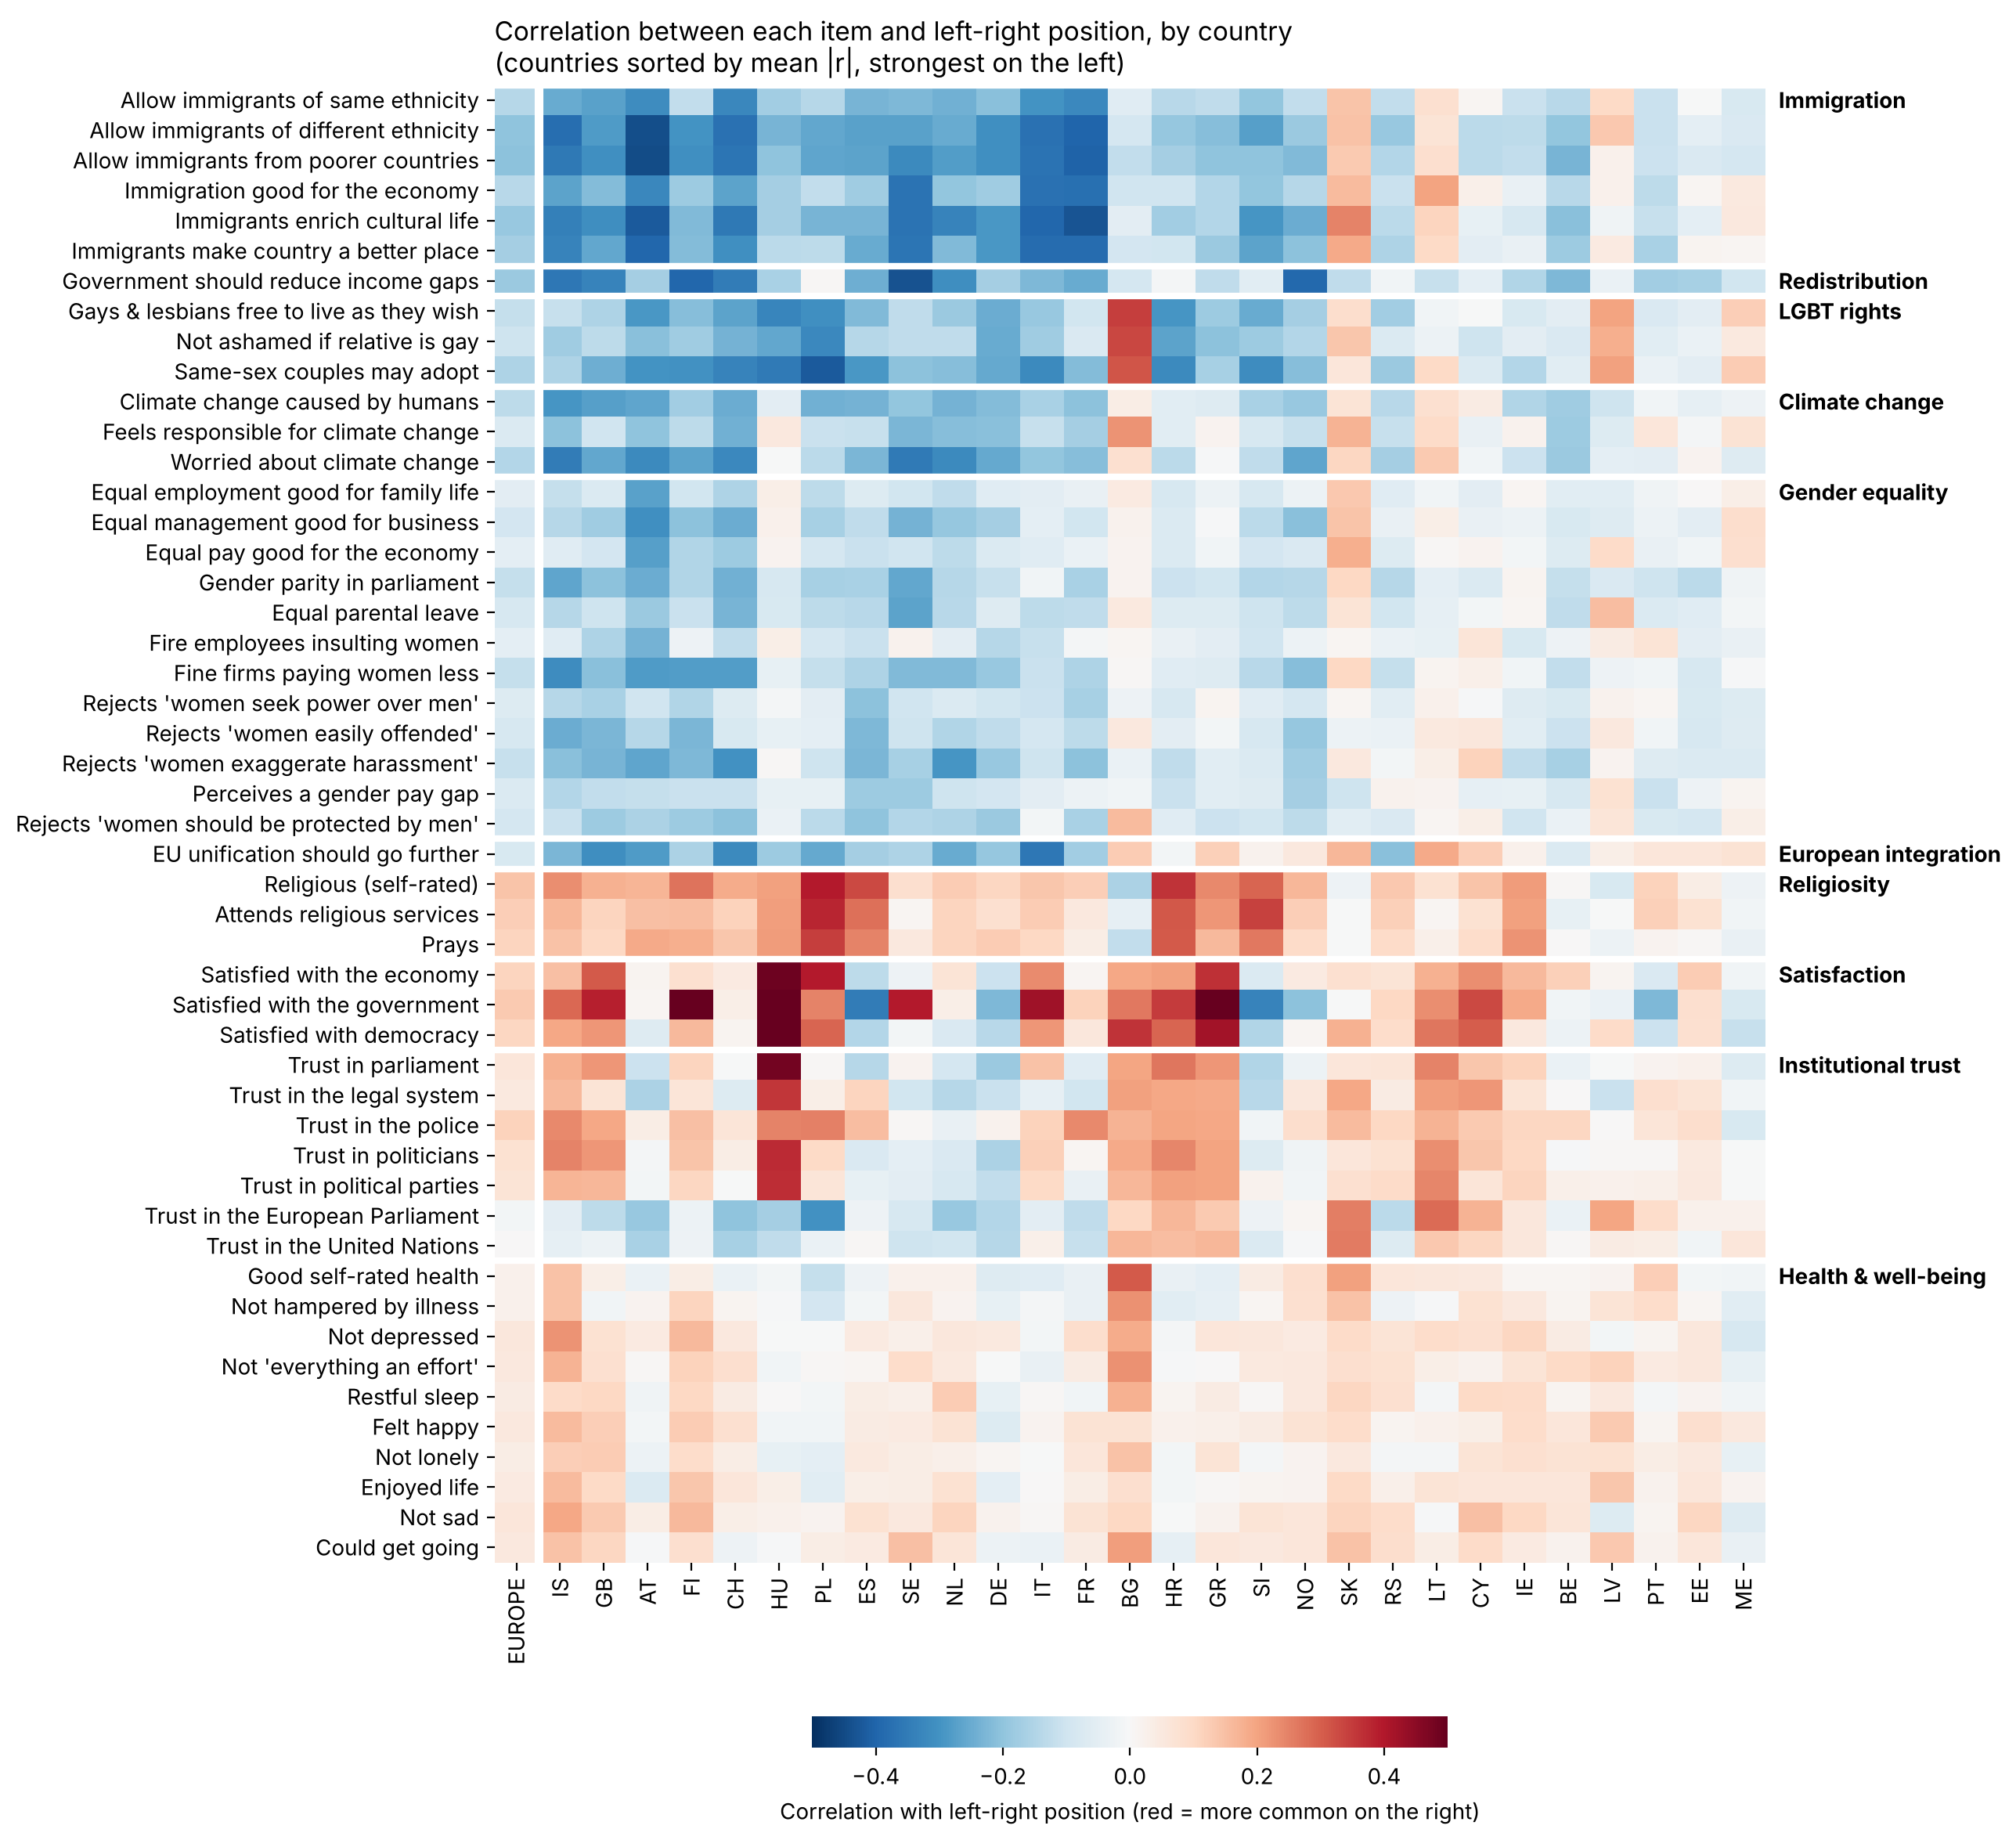

In [6]:
table_pays_lr = p2.table_position_pays(df, items)
p2.figure_heatmap(table_pays_lr, items)

**À retenir.**
- **En moyenne,** les opinions favorables à l'immigration, à la redistribution, aux droits LGBT et à la lutte contre le changement climatique sont plus fréquentes à gauche. La religiosité, la satisfaction et la confiance dans la police sont plus fréquentes à droite. La santé n'est presque pas liée à la position politique.
- **L'opposition gauche-droite est très marquée** en Islande, au Royaume-Uni, en Autriche, en Finlande et en Suisse. Elle est **presque absente** en Estonie, au Monténégro, au Portugal et en Lettonie.
- **Dans plusieurs pays de l'Est, les couleurs s'inversent** (Bulgarie, Lettonie, Lituanie, Slovaquie). En Bulgarie, par exemple, l'adoption par les couples de même sexe est plus soutenue à droite. Une explication possible : la « gauche » y désigne souvent les partis issus de l'ancien parti communiste, conservateurs sur les mœurs.
- **La satisfaction envers le gouvernement dépend de qui gouverne** (voir ci-dessous) : elle est liée à la droite là où la droite gouverne, et à la gauche là où la gauche gouverne.

Deux vérifications chiffrées :

In [7]:
# 1. Satisfaction envers le gouvernement : signe selon le pays
print(table_pays_lr.loc["Satisfied with the government"].sort_values().round(2).to_string())

# 2. Pays par pays ou tous pays mélangés ?
for item in ["europe_integration", "immig_culture"]:
    tous_pays = p2.corr_ponderee(df[item], df["lrscale"], df[p2.POIDS])
    pays_par_pays = table_pays_lr.loc[p2.LIBELLES[item]].mean()
    print(f"{p2.LIBELLES[item]} : tous pays mélangés {tous_pays:.2f}, pays par pays {pays_par_pays:.2f}")

cntry
ES   -0.35
SI   -0.33
DE   -0.22
PT   -0.22
NO   -0.21
ME   -0.08
LV   -0.03
BE   -0.02
SK   -0.00
AT    0.01
NL    0.03
CH    0.03
EE    0.08
RS    0.10
FR    0.11
IE    0.19
LT    0.23
PL    0.25
BG    0.26
IS    0.29
CY    0.33
HR    0.35
GB    0.39
SE    0.40
IT    0.42
GR    0.51
FI    0.56
HU    0.62
EU unification should go further : tous pays mélangés -0.20, pays par pays -0.08
Immigrants enrich cultural life : tous pays mélangés -0.29, pays par pays -0.19


- **Satisfaction envers le gouvernement.** La corrélation est positive en Hongrie, en Finlande, en Grèce et en Italie (gouvernements de droite au moment de l'enquête, 2023-2024), et négative en Espagne, en Slovénie, en Allemagne et au Portugal (gouvernements de gauche). C'est une opinion *partisane*, pas une opinion « de droite ».
- **Mélanger tous les pays surestime les liens :** -0,20 au lieu de -0,08 pour l'Europe, -0,29 au lieu de -0,19 pour l'immigration. D'où notre choix de calculer pays par pays.

## 2.5 Quels domaines sont liés à la position et à l'extrémité ? (figure 2 de Baldassarri et Gelman)

Pour chaque question, deux points :
- **en bleu, la corrélation avec la position gauche-droite.** Comme chez Baldassarri et Gelman, on retourne les questions pour que cette corrélation soit positive : *(rev.)* signifie qu'on lit la question à l'envers. Par exemple, « Same-sex couples may adopt (rev.) » se lit « être contre l'adoption ».
- **en orange, le lien entre l'extrémité et l'intensité de l'opinion.** L'intensité mesure à quel point la réponse s'éloigne de la moyenne du pays, dans un sens ou dans l'autre. Elle répond à la question : les personnes très à gauche ou très à droite ont-elles des opinions plus tranchées ?

    On ne corrèle pas directement l'extrémité avec l'opinion, parce qu'une personne très à gauche et une personne très à droite ont la même extrémité mais des opinions opposées : les deux s'annuleraient.

,r_position,r_extremity
group,,
Redistribution,0.19,0.07
Immigration,0.17,0.11
LGBT rights,0.13,0.07
Religiosity,0.13,0.04
Satisfaction,0.12,0.12
Climate change,0.12,0.07
Gender equality,0.08,0.04
European integration,0.08,0.13
Institutional trust,0.05,0.08


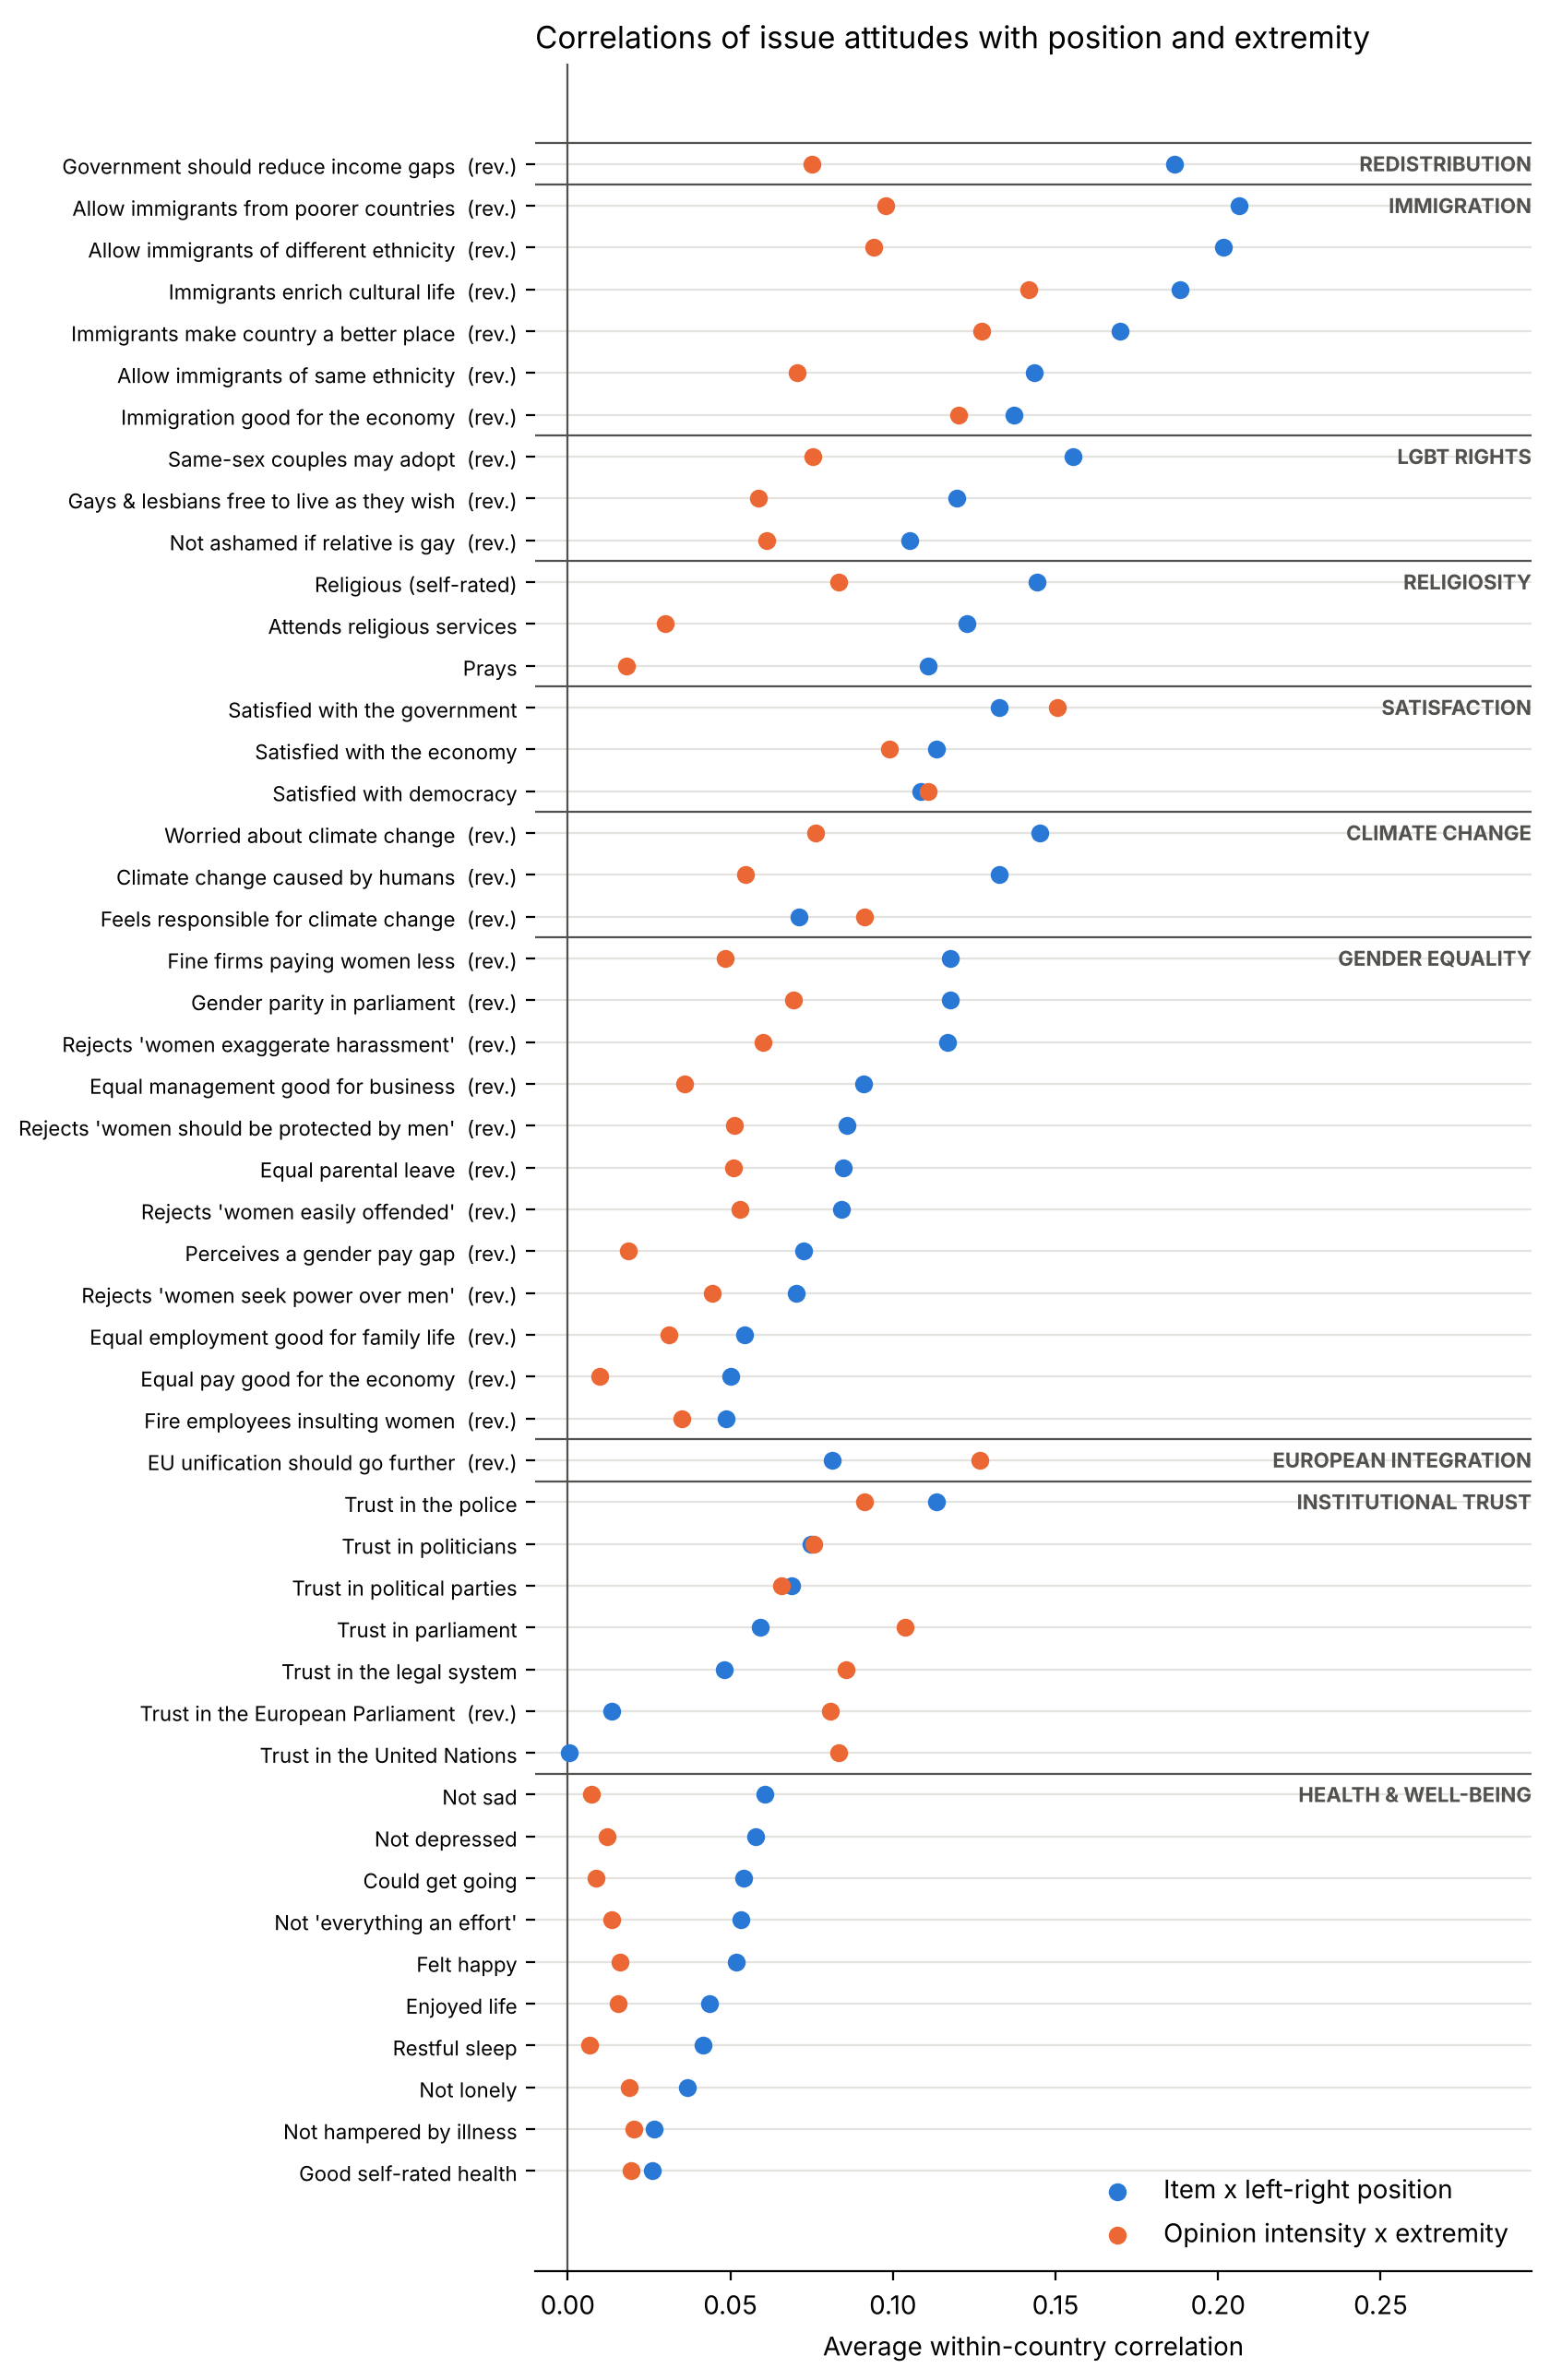

In [8]:
df_intensite = p2.intensite(df, items)
table = p2.table_bg(table_pays_lr, df_intensite, items)
p2.figure_bg(table)

table.groupby("group")[["r_position", "r_extremity"]].mean().sort_values("r_position", ascending=False)

**À retenir.**
- **Points bleus : deux sujets dominent.** La **redistribution** (0,19) et **l'immigration** (0,17) sont les plus liées à la position gauche-droite. Viennent ensuite les droits LGBT, la religion, la satisfaction et le climat (environ 0,12), puis l'égalité femmes-hommes et l'Europe (0,08). La confiance dans les institutions et la santé ferment la marche (0,05).

    L'opposition gauche-droite européenne combine donc un axe **économique** (redistribution) et un axe **culturel** (immigration, mœurs, religion), comme chez Baldassarri et Gelman. Les corrélations sont toutefois plus faibles qu'aux États-Unis (au maximum 0,21 ici, contre environ 0,33 dans l'article).
- **Points orange : l'extrémité est surtout liée au rapport au système.** Les personnes aux extrêmes ont des opinions plus tranchées sur l'Europe (0,13), la satisfaction (0,12) et l'immigration (0,11). Sur l'Europe et la confiance dans les institutions, le point orange dépasse même le point bleu : ces sujets opposent davantage **le centre aux extrêmes** que la gauche à la droite.

## 2.6 Synthèse

1. **Les opinions des Européens sont faiblement mais systématiquement liées entre elles,** et la démographie ne l'explique pas. Comme chez DellaPosta et al., des sujets sans rapport logique (l'immigration et les droits LGBT) vont ensemble.
2. **La position gauche-droite est surtout liée à la redistribution et à l'immigration,** puis aux mœurs et à la religion. La santé n'y est presque pas liée.
3. **Ces liens varient beaucoup selon les pays.** Ils s'inversent dans plusieurs pays de l'Est.
4. **L'extrémité n'est pas la même chose que la position :** elle est liée au rejet ou à l'adhésion au système (Europe, institutions).

**Limites.**
- Une corrélation ne prouve pas une relation de cause à effet.
- L'ESS11 ne couvre qu'une seule année.
- La forte non-réponse à l'échelle gauche-droite dans certains pays.

**Vers la partie 3 :** les domaines les plus liés à la position politique (immigration, redistribution, mœurs) sont ceux dont la partie 3 étudie l'évolution selon l'âge.

*Références :* Baldassarri & Gelman (2008), *American Journal of Sociology* 114(2) ; DellaPosta, Shi & Macy (2015), *American Journal of Sociology* 120(5) ; ESS ERIC (2024), *ESS round 11*, licence CC BY-NC-SA 4.0.